<a href="https://colab.research.google.com/github/henrypitts/Baseball-Colab-Tools/blob/main/Blast_Motion_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load CSV
file_path = 'RheaJuly17.csv'
df = pd.read_csv(file_path)

# Numeric-only columns
numeric_df = df.select_dtypes(include='number')

# Compute statistics
mean_values = numeric_df.mean()
std_values = numeric_df.std()
min_values = numeric_df.min()
max_values = numeric_df.max()

# Format range as string "min – max"
range_str = min_values.astype(str) + " – " + max_values.astype(str)

# Combine into summary DataFrame
summary_df = pd.DataFrame({
    'Average': mean_values,
    'Standard Deviation': std_values,
    'Range (Min – Max)': range_str
})

# Show summary
summary_df


,Average,Standard Deviation,Range (Min – Max)
Plane Score,58.315789,7.348856,39.0 – 72.0
Connection Score,64.342105,11.711109,36.0 – 80.0
Rotation Score,57.052632,8.491482,40.0 – 80.0
Bat Speed (mph),68.568421,3.414920,56.0 – 73.6
Rotational Acceleration (g),15.802632,3.486537,8.9 – 25.3
On Plane Efficiency (%),75.078947,7.360896,56.0 – 89.0
Attack Angle (deg),10.552632,6.781124,-10.0 – 21.0
Early Connection (deg),95.342105,8.473413,75.0 – 109.0
Connection at Impact (deg),86.105263,8.579641,48.0 – 97.0
Vertical Bat Angle (deg),-32.421053,12.133562,-46.0 – 21.0


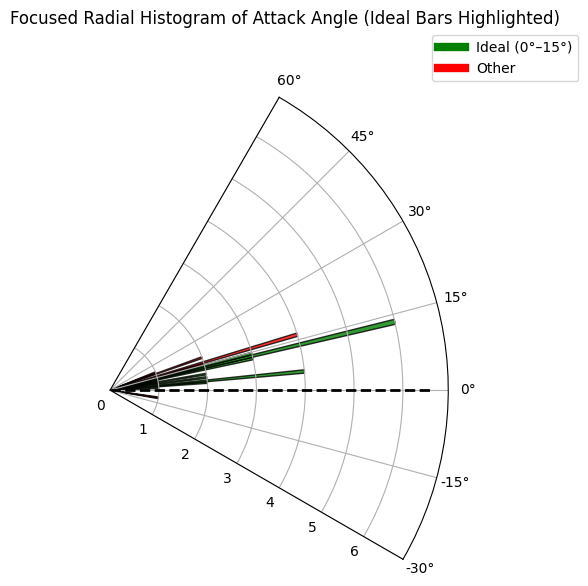

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Prepare attack angle data
attack_angles = df["Attack Angle (deg)"].dropna()

# Convert to radians
radians = np.deg2rad(attack_angles)
degree_bins = np.arange(-180, 181, 1)
rad_bins = np.deg2rad(degree_bins)
bin_counts, _ = np.histogram(attack_angles, bins=degree_bins)

# Centers and widths for polar histogram
bin_centers_rad = np.deg2rad((degree_bins[:-1] + degree_bins[1:]) / 2)
width_rad = np.deg2rad(1)

# Step 2: Define ideal angle range (0° to 15°)
ideal_mask = (np.rad2deg(bin_centers_rad) >= 0) & (np.rad2deg(bin_centers_rad) <= 15)
bar_colors = ['green' if is_ideal else 'red' for is_ideal in ideal_mask]

# Step 3: Define plot range
angle_min = -30
angle_max = 60

# Step 4: Create the polar plot
fig = plt.figure(figsize=(10, 6))
ax = plt.subplot(111, polar=True)

# Plot bars with conditional coloring
bars = ax.bar(bin_centers_rad, bin_counts, width=width_rad, bottom=0.0,
              color=bar_colors, edgecolor="black", alpha=0.8)

# Add 0° reference line
ax.plot([0, 0], [0, max(bin_counts) * 1.1], color='black', linestyle='--', linewidth=2, label='0° Reference')

# Configure polar axis
ax.set_theta_zero_location("E")   # 0° is to the right
ax.set_theta_direction(1)         # Counterclockwise (positive above horizontal)
ax.set_thetamin(angle_min)
ax.set_thetamax(angle_max)
ax.set_ylim(0, None)

# Custom tick marks
ticks = np.arange(angle_min, angle_max + 1, 15)
ax.set_xticks(np.deg2rad(ticks))
ax.set_xticklabels([f"{int(t)}°" for t in ticks])

# Title and legend
green_patch = plt.Line2D([0], [0], color='green', lw=6, label='Ideal (0°–15°)')
orange_patch = plt.Line2D([0], [0], color='red', lw=6, label='Other')
ax.set_title("Focused Radial Histogram of Attack Angle (Ideal Bars Highlighted)", va='bottom', pad=50)
ax.legend(handles=[green_patch, orange_patch], loc='upper right', bbox_to_anchor=(1.15, 1.15))

plt.show()


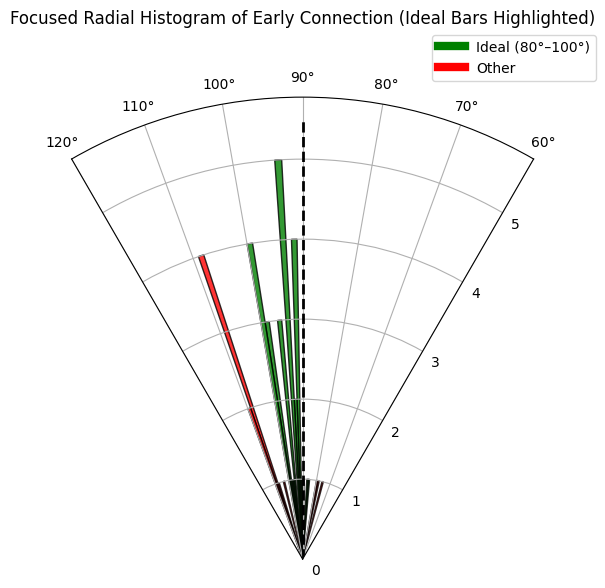

In [ ]:
# Prepare early connection data
early_conn = df["Early Connection (deg)"].dropna()

# Convert to radians for polar plotting
radians_ec = np.deg2rad(early_conn)
degree_bins_ec = np.arange(-180, 181, 1)
rad_bins_ec = np.deg2rad(degree_bins_ec)
bin_counts_ec, _ = np.histogram(early_conn, bins=degree_bins_ec)

# Centers and width
bin_centers_rad_ec = np.deg2rad((degree_bins_ec[:-1] + degree_bins_ec[1:]) / 2)
width_rad_ec = np.deg2rad(1)

# Define ideal range for early connection (80°–100°)
ideal_min_ec = 80
ideal_max_ec = 100
ideal_mask_ec = (np.rad2deg(bin_centers_rad_ec) >= ideal_min_ec) & (np.rad2deg(bin_centers_rad_ec) <= ideal_max_ec)
bar_colors_ec = ['green' if is_ideal else 'red' for is_ideal in ideal_mask_ec]

# Define angle window to focus on
angle_min_ec = 60
angle_max_ec = 120

# Plotting
fig = plt.figure(figsize=(10, 6))
ax = plt.subplot(111, polar=True)

# Plot histogram bars
bars = ax.bar(bin_centers_rad_ec, bin_counts_ec, width=width_rad_ec, bottom=0.0,
              color=bar_colors_ec, edgecolor="black", alpha=0.8)

# Add reference line at 90°
ax.plot([np.deg2rad(90), np.deg2rad(90)], [0, max(bin_counts_ec) * 1.1],
        color='black', linestyle='--', linewidth=2, label='90° Reference')

# Axis config
ax.set_theta_zero_location("E")
ax.set_theta_direction(1)
ax.set_thetamin(angle_min_ec)
ax.set_thetamax(angle_max_ec)
ax.set_ylim(0, None)

# Ticks
ticks_ec = np.arange(angle_min_ec, angle_max_ec + 1, 10)
ax.set_xticks(np.deg2rad(ticks_ec))
ax.set_xticklabels([f"{int(t)}°" for t in ticks_ec])

# Title and legend
green_patch_ec = plt.Line2D([0], [0], color='green', lw=6, label='Ideal (80°–100°)')
orange_patch_ec = plt.Line2D([0], [0], color='red', lw=6, label='Other')
ax.set_title("Focused Radial Histogram of Early Connection (Ideal Bars Highlighted)",
             va='bottom', pad=50)
ax.legend(handles=[green_patch_ec, orange_patch_ec], loc='upper right', bbox_to_anchor=(1.15, 1.15))

plt.show()


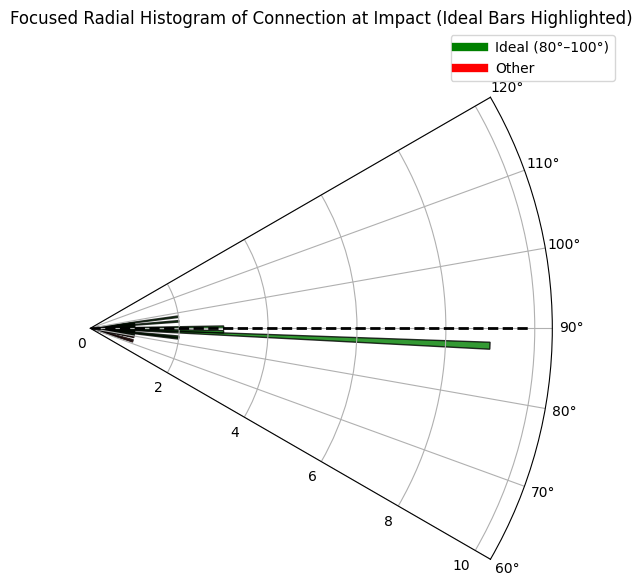

In [ ]:
# Prepare connection at impact data
conn_impact = df["Connection at Impact (deg)"].dropna()

# Convert to radians for polar plotting
radians_ci = np.deg2rad(conn_impact)
degree_bins_ci = np.arange(-180, 181, 1)
rad_bins_ci = np.deg2rad(degree_bins_ci)
bin_counts_ci, _ = np.histogram(conn_impact, bins=degree_bins_ci)

# Centers and widths
bin_centers_rad_ci = np.deg2rad((degree_bins_ci[:-1] + degree_bins_ci[1:]) / 2)
width_rad_ci = np.deg2rad(1)

# Define ideal range for connection at impact (85°–95°)
ideal_min_ci = 80
ideal_max_ci = 100
ideal_mask_ci = (np.rad2deg(bin_centers_rad_ci) >= ideal_min_ci) & (np.rad2deg(bin_centers_rad_ci) <= ideal_max_ci)
bar_colors_ci = ['green' if is_ideal else 'red' for is_ideal in ideal_mask_ci]

# Define viewing angle range
angle_min_ci = 60
angle_max_ci = 120

# Plotting
fig = plt.figure(figsize=(10, 6))
ax = plt.subplot(111, polar=True)

# Plot histogram bars
bars = ax.bar(bin_centers_rad_ci, bin_counts_ci, width=width_rad_ci, bottom=0.0,
              color=bar_colors_ci, edgecolor="black", alpha=0.8)

# Add reference line at 90°
ax.plot([np.deg2rad(90), np.deg2rad(90)], [0, max(bin_counts_ci) * 1.1],
        color='black', linestyle='--', linewidth=2, label='90° Reference')

# Axis configuration
ax.set_theta_zero_location("S")
ax.set_theta_direction(1)
ax.set_thetamin(angle_min_ci)
ax.set_thetamax(angle_max_ci)
ax.set_ylim(0, None)

# Custom ticks
ticks_ci = np.arange(angle_min_ci, angle_max_ci + 1, 10)
ax.set_xticks(np.deg2rad(ticks_ci))
ax.set_xticklabels([f"{int(t)}°" for t in ticks_ci])

# Title and legend
green_patch_ci = plt.Line2D([0], [0], color='green', lw=6, label='Ideal (80°–100°)')
orange_patch_ci = plt.Line2D([0], [0], color='red', lw=6, label='Other')
ax.set_title("Focused Radial Histogram of Connection at Impact (Ideal Bars Highlighted)",
             va='bottom', pad=50)
ax.legend(handles=[green_patch_ci, orange_patch_ci], loc='upper right', bbox_to_anchor=(1.15, 1.15))

plt.show()


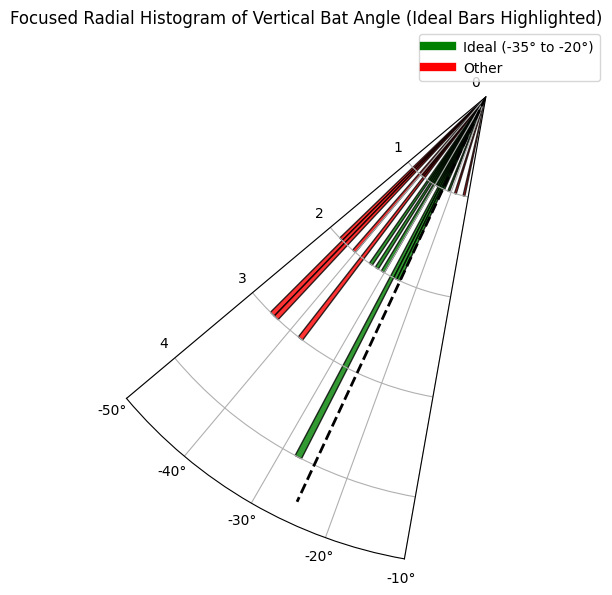

In [ ]:
# Prepare vertical bat angle data
vbat = df["Vertical Bat Angle (deg)"].dropna()

# Convert to radians for polar plotting
radians_vbat = np.deg2rad(vbat)
degree_bins_vbat = np.arange(-180, 181, 1)
rad_bins_vbat = np.deg2rad(degree_bins_vbat)
bin_counts_vbat, _ = np.histogram(vbat, bins=degree_bins_vbat)

# Centers and widths
bin_centers_rad_vbat = np.deg2rad((degree_bins_vbat[:-1] + degree_bins_vbat[1:]) / 2)
width_rad_vbat = np.deg2rad(1)

# Define ideal range for vertical bat angle (-20° to -30°)
ideal_min_vbat = -35
ideal_max_vbat = -20
ideal_mask_vbat = (np.rad2deg(bin_centers_rad_vbat) >= ideal_min_vbat) & (np.rad2deg(bin_centers_rad_vbat) <= ideal_max_vbat)
bar_colors_vbat = ['green' if is_ideal else 'red' for is_ideal in ideal_mask_vbat]

# Viewing angle range
angle_min_vbat = -50
angle_max_vbat = -10

# Plotting
fig = plt.figure(figsize=(10, 6))
ax = plt.subplot(111, polar=True)

# Plot histogram bars
bars = ax.bar(bin_centers_rad_vbat, bin_counts_vbat, width=width_rad_vbat, bottom=0.0,
              color=bar_colors_vbat, edgecolor="black", alpha=0.8)

# Add reference line at -25° (middle of ideal range)
ax.plot([np.deg2rad(-25), np.deg2rad(-25)], [0, max(bin_counts_vbat) * 1.1],
        color='black', linestyle='--', linewidth=2, label='-25° Reference')

# Axis config (rotated 90° clockwise)
ax.set_theta_zero_location("S")  # 0° at bottom
ax.set_theta_direction(1)        # counterclockwise
ax.set_thetamin(angle_min_vbat)
ax.set_thetamax(angle_max_vbat)
ax.set_ylim(0, None)

# Ticks
ticks_vbat = np.arange(angle_min_vbat, angle_max_vbat + 1, 10)
ax.set_xticks(np.deg2rad(ticks_vbat))
ax.set_xticklabels([f"{int(t)}°" for t in ticks_vbat])

# Title and legend
green_patch_vbat = plt.Line2D([0], [0], color='green', lw=6, label='Ideal (-35° to -20°)')
orange_patch_vbat = plt.Line2D([0], [0], color='red', lw=6, label='Other')
ax.set_title("Focused Radial Histogram of Vertical Bat Angle (Ideal Bars Highlighted)",
             va='bottom', pad=50)
ax.legend(handles=[green_patch_vbat, orange_patch_vbat], loc='upper right', bbox_to_anchor=(1.15, 1.15))

plt.show()


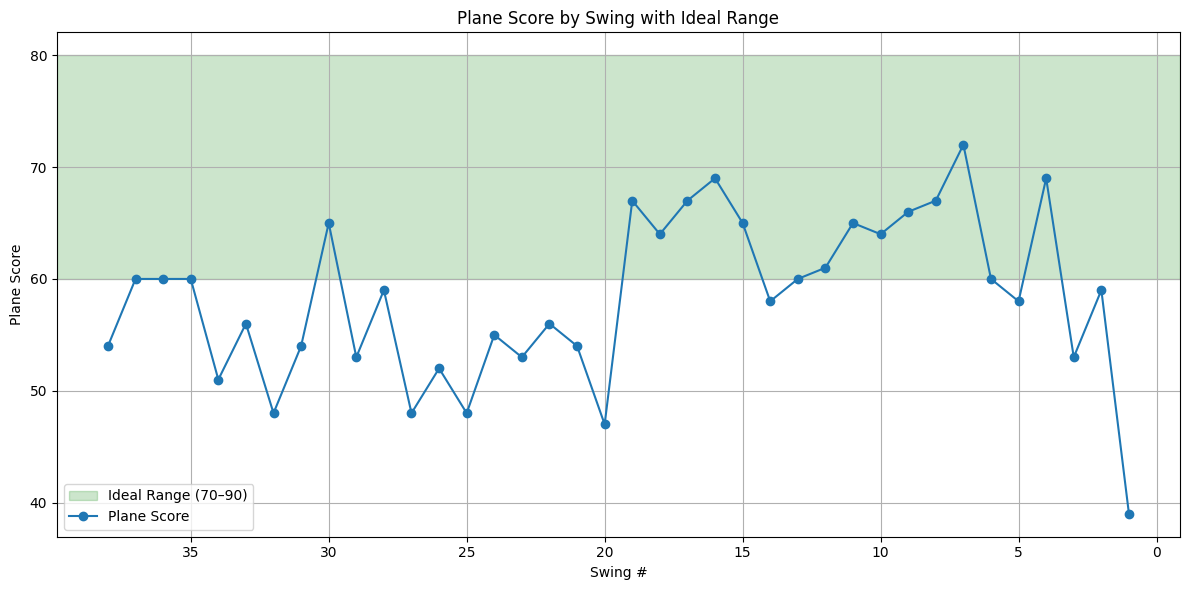

In [ ]:
import matplotlib.pyplot as plt

# Example for Plane Score
df = df.sort_values('Date', ascending=False).reset_index(drop=True)
df['Swing #'] = df.index + 1  # Most recent is Swing 1

# Start plotting
plt.figure(figsize=(12, 6))

# Add ideal performance band — change these values based on metric
plt.axhspan(60, 80, color='green', alpha=0.2, label='Ideal Range (70–90)')

# Plot the line
plt.plot(df['Swing #'], df['Plane Score'], marker='o', label='Plane Score')

# Invert x-axis to show most recent first
plt.gca().invert_xaxis()

# Labels and formatting
plt.title('Plane Score by Swing with Ideal Range')
plt.xlabel('Swing #')
plt.ylabel('Plane Score')
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


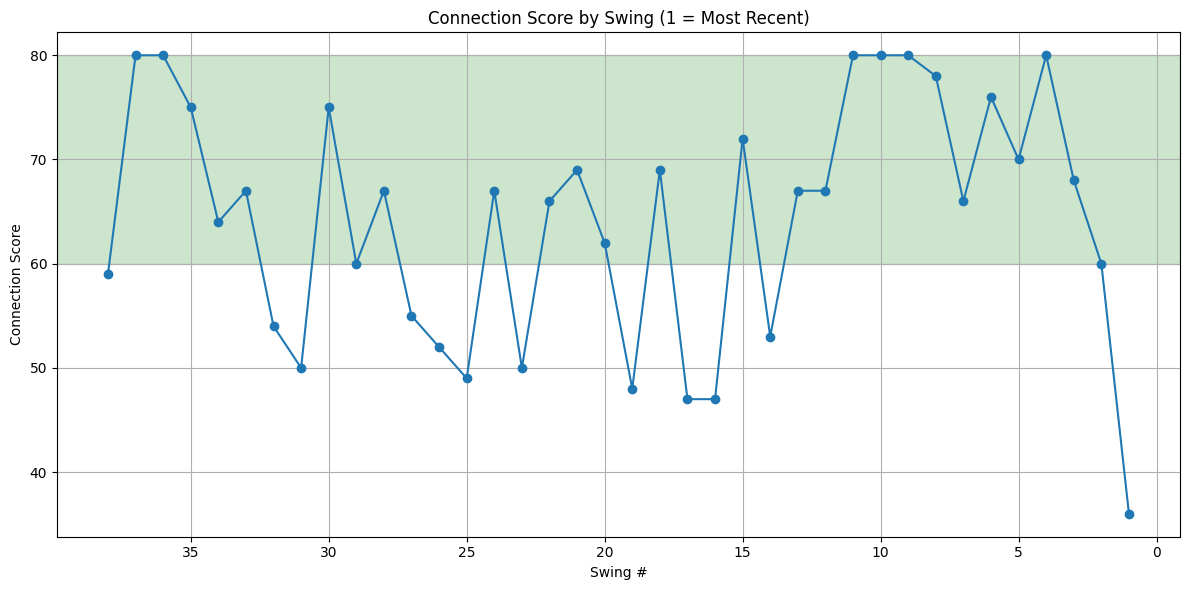

In [ ]:
# Create the line plot for Connection Score using the same Swing # index
plt.figure(figsize=(12, 6))
plt.plot(df['Swing #'], df['Connection Score'], marker='o', linestyle='-')

# Add ideal performance band — change these values based on metric
plt.axhspan(60, 80, color='green', alpha=0.2, label='Ideal Range (70–90)')

# Formatting
plt.title('Connection Score by Swing (1 = Most Recent)')
plt.xlabel('Swing #')
plt.ylabel('Connection Score')
plt.gca().invert_xaxis()  # Most recent swing on the left
plt.grid(True)
plt.tight_layout()

plt.show()


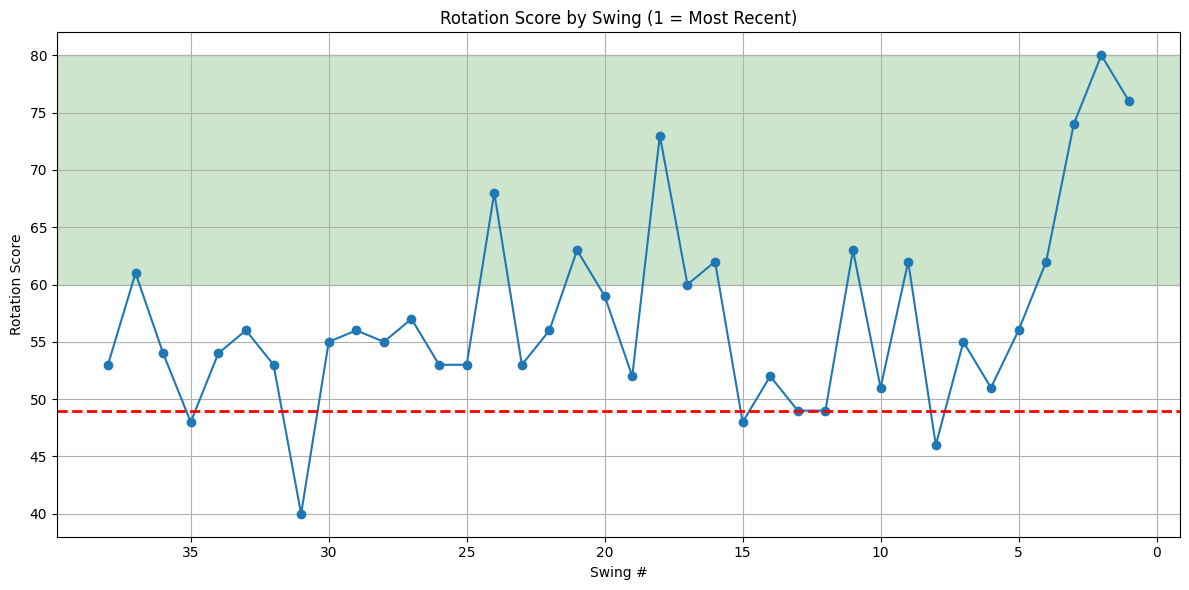

In [ ]:
# Create the line plot for Rotation Score using the same Swing # index
plt.figure(figsize=(12, 6))
plt.plot(df['Swing #'], df['Rotation Score'], marker='o', linestyle='-')

# Add ideal performance band — change these values based on metric
plt.axhspan(60, 80, color='green', alpha=0.2, label='Ideal Range (70–90)')

# Add a horizontal line for Team Average at 49%
plt.axhline(49, color='red', linestyle='--', linewidth=2, label='Team Average (49%)')

# Formatting
plt.title('Rotation Score by Swing (1 = Most Recent)')
plt.xlabel('Swing #')
plt.ylabel('Rotation Score')
plt.gca().invert_xaxis()  # Most recent swing on the left
plt.grid(True)
plt.tight_layout()

plt.show()


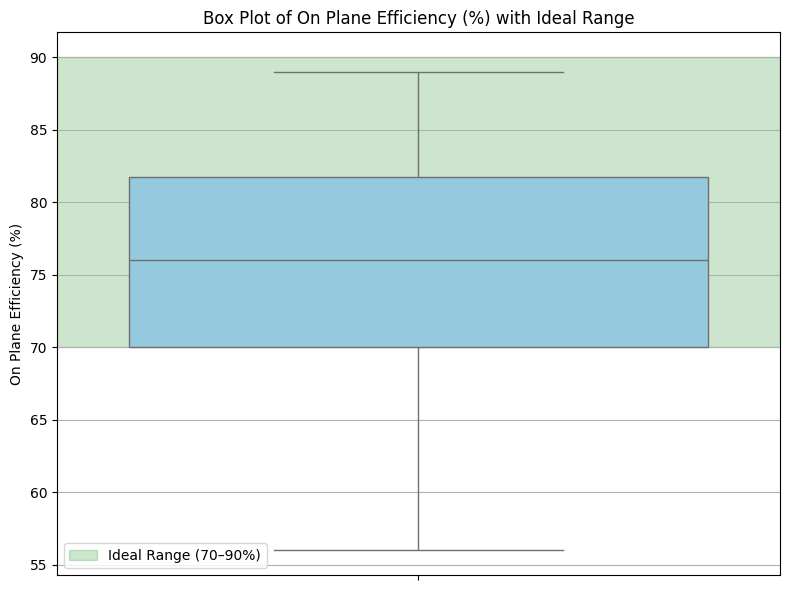

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: sort if needed
df = df.sort_values('Date', ascending=False).reset_index(drop=True)

# Create the box plot with performance band
plt.figure(figsize=(8, 6))

# Add performance band from 70 to 90 percent
plt.axhspan(70, 90, color='green', alpha=0.2, label='Ideal Range (70–90%)')

# Plot the boxplot
sns.boxplot(y=df['On Plane Efficiency (%)'], color='skyblue')



# Formatting
plt.title('Box Plot of On Plane Efficiency (%) with Ideal Range')
plt.ylabel('On Plane Efficiency (%)')
plt.grid(True, axis='y')
plt.legend()
plt.tight_layout()

plt.show()


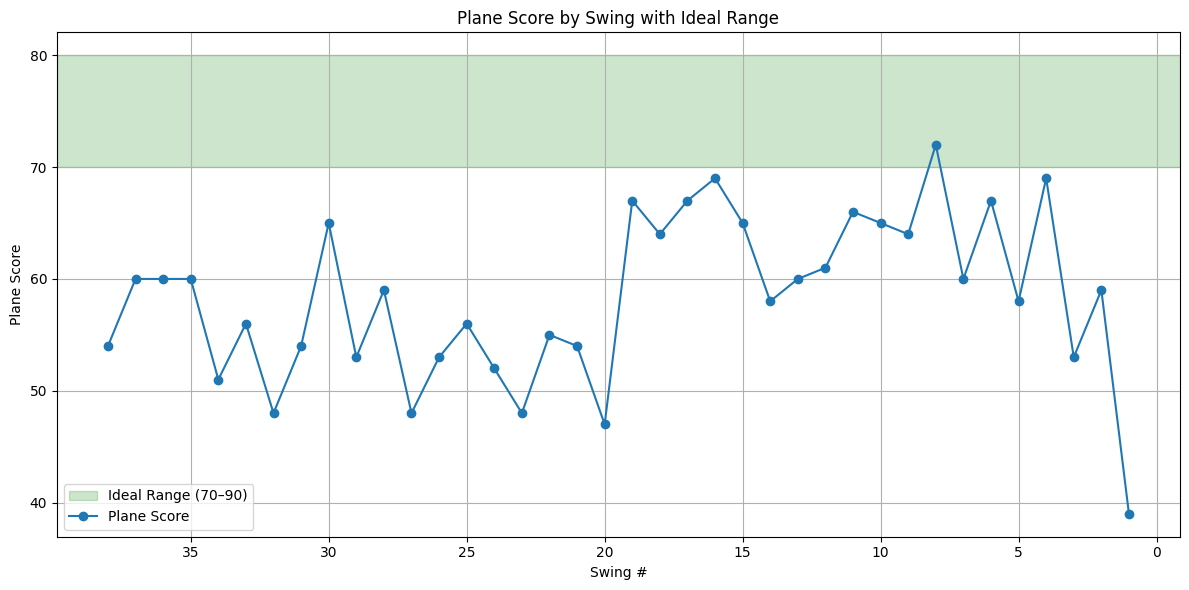

In [ ]:
import matplotlib.pyplot as plt

# Example for Plane Score
df = df.sort_values('Date', ascending=False).reset_index(drop=True)
df['Swing #'] = df.index + 1  # Most recent is Swing 1

# Start plotting
plt.figure(figsize=(12, 6))

# Add ideal performance band — change these values based on metric
plt.axhspan(70, 80, color='green', alpha=0.2, label='Ideal Range (70–90)')

# Plot the line
plt.plot(df['Swing #'], df['Plane Score'], marker='o', label='Plane Score')

# Invert x-axis to show most recent first
plt.gca().invert_xaxis()

# Labels and formatting
plt.title('Plane Score by Swing with Ideal Range')
plt.xlabel('Swing #')
plt.ylabel('Plane Score')
plt.grid(True)
plt.legend()
plt.tight_layout()

plt.show()


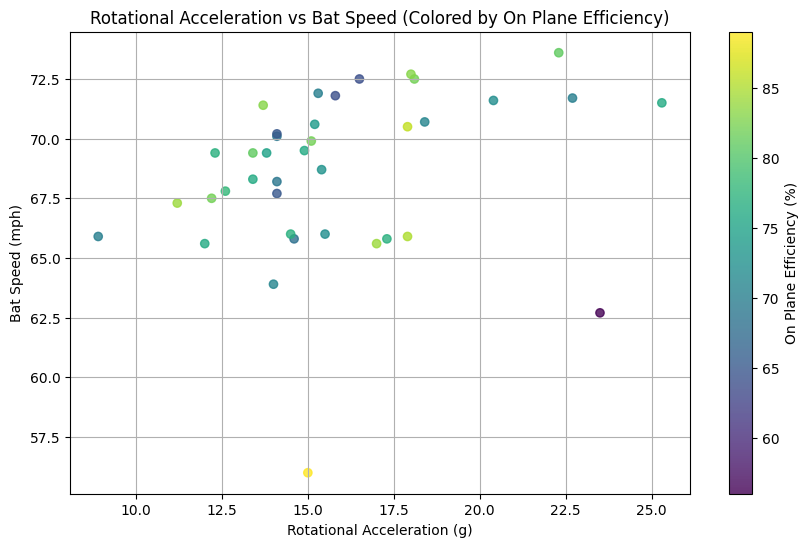

In [ ]:


# Extract relevant columns
rot_accel = df["Rotational Acceleration (g)"]
bat_speed = df["Bat Speed (mph)"]
on_plane_efficiency = df["On Plane Efficiency (%)"]

# Create scatter plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    rot_accel, bat_speed,
    c=on_plane_efficiency,
    cmap='viridis',
    alpha=0.8
)
plt.title("Rotational Acceleration vs Bat Speed (Colored by On Plane Efficiency)")
plt.xlabel("Rotational Acceleration (g)")
plt.ylabel("Bat Speed (mph)")
plt.grid(True)
cbar = plt.colorbar(scatter)
cbar.set_label("On Plane Efficiency (%)")
plt.show()


In [ ]:
mean_values = df_hybrid_scaled.mean(numeric_only=True)
std_values = df_hybrid_scaled.std(numeric_only=True)

# Combine into a summary DataFrame
summary_df = pd.DataFrame({
    'Average': mean_values,
    'Standard Deviation': std_values
})


# Show the summary statistics
summary_df

NameError: name 'df_hybrid_scaled' is not defined

In [ ]:
!pip -q install nbconvert

from pathlib import Path
from google.colab import files

# Find notebooks in Colab
notebooks = list(Path("/content").glob("*.ipynb"))

print("Available notebooks:")
for nb in notebooks:
    print(nb)

Available notebooks:
/content/Blast_Analysis.ipynb


In [ ]:
from google.colab import files

uploaded = files.upload()
notebook_path = next(iter(uploaded))

print(f"Notebook found: {notebook_path}")

Saving Blast_Analysis.ipynb to Blast_Analysis.ipynb
Notebook found: Blast_Analysis.ipynb


In [ ]:
from pathlib import Path
from IPython.display import display
from google.colab import files

# Select your notebook
notebook_path = Path("/content/Blast_Analysis.ipynb")

# Export to HTML
!jupyter nbconvert --to html "{notebook_path}" \
    --output "Notebook_Report.html" \
    --output-dir "/content"

# Download HTML
files.download("/content/Notebook_Report.html")

[NbConvertApp] Converting notebook /content/Blast_Analysis.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 10 image(s).
[NbConvertApp] Writing 1223920 bytes to /content/Notebook_Report.html


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>